# Comparison of some models with the data

In [ ]:
from utils import *

from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, make_scorer
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor

from skopt import BayesSearchCV, gp_minimize, load
from skopt.plots import plot_objective, plot_convergence, plot_evaluations
from skopt.space import Space, Real, Integer, Categorical
from skopt.callbacks import CheckpointSaver

from joblib import Parallel, delayed

import warnings
warnings.filterwarnings("ignore")

## Importing data

In [85]:
suffix = "states_votes_incentives"
raw_data = pd.read_csv(f"data/solar_panels_dataset_with_{suffix}.csv", index_col=0)

features = sorted(list(set(raw_data.columns) - {'state', 'cumulative num of residential PVs by 2016', 'number of buildings'}))

X = raw_data[features].to_numpy()
y = (raw_data['cumulative num of residential PVs by 2016']/raw_data['number of buildings']).to_numpy().reshape(-1,1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y!=0)

## XGBoost

In [3]:
xg_space = [
    Integer(10, 1000, name='n_estimators'),
    Integer(0, 50, name='max_leaves'),
    Real(1e-2, 10, prior='log-uniform', name='learning_rate'),
    Categorical([0, 5, 10, 15, 20, 25, 30, 35, 40], name='max_depth'),
]

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5)
all_scores = []

def cv_one(model, X, y, train_idx, test_idx):
    model.fit(X[train_idx], y[train_idx])
    y_pred = model.predict(X[test_idx])
    y_pred[np.isnan(y_pred)] = 1e20
    return r2_score(y[test_idx], y_pred)

def objective_xg(x):
    xc = x.copy()
    if xc[-1] == 0: xc[-1] = None
    params = {v: xv for v, xv in zip([v.name for v in xg_space], xc)}
    model = XGBRegressor(**params)
    scores = Parallel(n_jobs=8)(delayed(cv_one)(model, X_train, y_train, train, test) for train, test in rskf.split(X_train, y_train!=0))
    all_scores.append(scores)
    np.save(f"all_scores_{suffix}.npy", all_scores)

    return -np.nanmean(scores)

def timer_callback(res):
    timer.end_iter()
    timer.start_iter()

In [4]:
n_calls = 100
timer = IterTimer(n_calls)

timer.start_iter()
xg_opt = gp_minimize(objective_xg, xg_space, n_calls=n_calls, callback=[timer_callback, CheckpointSaver(f"opt_results_XG_{suffix}.pkl")], acq_func='LCB', n_jobs=8, n_initial_points=20)

KeyboardInterrupt: 

In [ ]:
fig, ax = plt.subplots()

maxs = np.maximum.accumulate(-xg_opt.func_vals)
maxs = np.clip(maxs, 0.5, np.inf)
ax.plot(maxs, linewidth=3)

ax.set_xlabel("Iterations")
ax.set_ylabel("R2 score")
ax.grid()

fig.tight_layout()

In [ ]:
best_x = xg_opt.x_iters[xg_opt.func_vals.argmin()]
best_params = {v: xv for v, xv in zip([v.name for v in xg_space], best_x)}
model = XGBRegressor(**best_params)
model.fit(X_train, y_train)

print(f"Best CV score: {-xg_opt.func_vals.min():.4f}")
print(f"Test score: {model.score(X_test, y_test):.4f}")
print(f"Best params: {str(best_params)}")

With states: 0.6522

With states and votes: 0.7202

With states, votes, and incentives: 0.7188

In [ ]:
_ = plot_objective(xg_opt)
plt.show()

### Best XGBoost

In [8]:
xg_opt = load(f"opt_results_XG_{suffix}.pkl")
best_x = xg_opt.x_iters[xg_opt.func_vals.argmin()]
best_params = {v: xv for v, xv in zip([v.name for v in xg_space], best_x)}
model = XGBRegressor(**best_params)
model.fit(X_train, y_train)
print(f"{model.score(X_test, y_test):.4f}")

0.7082


With states: 0.6505

With states and votes: 0.7124

With states, votes, and incentives: 0.7082

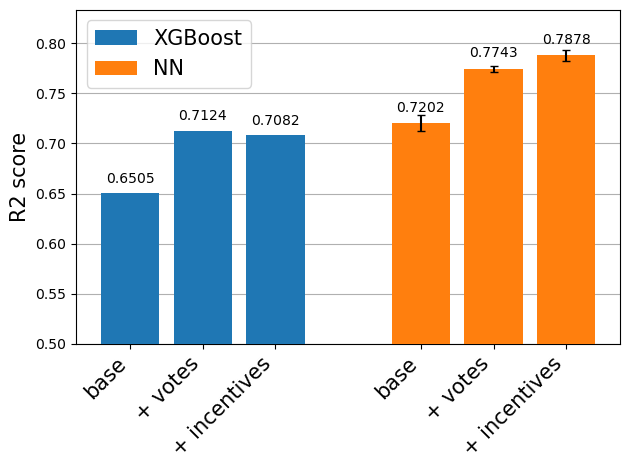

In [4]:
fig, ax = plt.subplots()

ax.bar([0, 1, 2], [0.6505, 0.7124, 0.7082], label="XGBoost", zorder=10)
ax.bar([4, 5, 6], [0.7202, 0.7743, 0.7878], yerr=[0.0080, 0.0033, 0.0057], label="NN", zorder=10, capsize=3)

for p, s in zip([0, 1, 2, 4, 5, 6], [0.6505, 0.7124, 0.7082, 0.7202, 0.7743, 0.7878]):
    ax.text(p, 1.015*s, s, ha='center')

ax.set_ylim(0.5)
ax.legend(fontsize=15)
ax.yaxis.grid(True)

ax.set_xticks([0, 1, 2, 4, 5, 6])
ax.set_xticklabels(["base", "+ votes", "+ incentives", "base", "+ votes", "+ incentives"], rotation=45, ha='right', fontsize=15)
ax.set_ylabel("R2 score", fontsize=15)

fig.tight_layout()
# fig.savefig("../images/best_models_barplot.png", dpi=150)

### Best features

In [ ]:
features_plot = features
features_plot[:11] = ['avg GHI (W/m^2)',
            'number of households',
            'housing density (/mile^2)',
            'median income (inflation adjusted $)',
            '% housing occupied',
            '% housing occupied by renters',
            'avg years of education',
            'median age',
            'racial diversity (Gini Simpson index)',
            'fraction of dem votes',
            'level of incentives']

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

importances = model.feature_importances_
feat_plot = np.array(features_plot)[importances.argsort()[-10:]]

ax.barh(range(len(feat_plot)), importances[importances.argsort()[-10:]])
ax.set_yticks(range(len(feat_plot)))
ax.set_yticklabels(feat_plot);

fig.tight_layout()
# fig.savefig("XG_all_features.png", dpi=150)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

importances = model.feature_importances_[:11]
feat_plot = np.array(features_plot[:11])[importances.argsort()]

ax.barh(range(len(feat_plot)), importances[importances.argsort()])
ax.set_yticks(range(len(feat_plot)))
ax.set_yticklabels(feat_plot);

fig.tight_layout()
# fig.savefig("XG_features.png", dpi=150)

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

y_pred = model.predict(X_test)

minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax.scatter(y_test, y_pred, zorder=10)
ax.plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax.set_title(f"Best model, test R2 score: {model.score(X_test, y_test):.4f}", fontsize=15)
ax.set_xlabel("True value", fontsize=15)
ax.set_ylabel("Predicted value", fontsize=15)
# ax[1].set_xlim(minval, maxval)
# ax.set_ylim(minval, maxval)
ax.set_box_aspect(1)
ax.set_xscale('log')
ax.set_yscale('log')

fig.tight_layout()
# fig.savefig("XG_parity.png", dpi=150)

## NN

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader
import torch.utils.data as data_utils
device = 'cpu'

In [4]:
def train_model(model, X_train, y_train, X_val, y_val, lr=0.001, n_epochs=50, batch_size=32, verbose=False):
    #convert to tensors (for Pytorch)
    X_train_tensor = torch.tensor(X_train).to(device).float()
    y_train_tensor = torch.tensor(y_train).to(device).float()
    X_val_tensor = torch.tensor(X_val).to(device).float()
    y_val_tensor = torch.tensor(y_val).to(device).float()
    
    #intialize neural network
    n_samples, n_features = X_train_tensor.shape
    
    #initialize mse loss function
    criterion = torch.nn.MSELoss(reduction='mean')
    
    #keep track of losses
    train_losses = []
    val_losses = []
    train_r2 = []
    val_r2 = []
    
    #train with SGD
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    # scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=1e-6)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.7)
    for e in range(n_epochs):
        model.train()
        y_pred = torch.zeros(y_train_tensor.shape).to(device)
        for batch_start in range(0, n_samples, batch_size):
            optimizer.zero_grad()
            X_batch = X_train_tensor[batch_start:batch_start+batch_size]
            y_batch = y_train_tensor[batch_start:batch_start+batch_size]
            y_pred_batch = model(X_batch)
            loss = criterion(y_pred_batch, y_batch)
            loss.backward()
            optimizer.step()
            y_pred[batch_start:batch_start+batch_size] = y_pred_batch
            
        train_losses.append(criterion(y_pred, y_train_tensor).item())
        y_pred = y_pred.detach().cpu().numpy()
        nanmask = ~np.isnan(y_pred)
        train_r2.append(r2_score(y_train[nanmask], y_pred[nanmask]))
        
        #evaluate model:
        model.eval()
        with torch.no_grad():
            y_pred = model(X_val_tensor)
            val_losses.append(criterion(y_pred, y_val_tensor).item())
            y_pred = y_pred.detach().cpu().numpy()
            nanmask = ~np.isnan(y_pred)
            val_r2.append(r2_score(y_val[nanmask], y_pred[nanmask]))
        
        if verbose and e%(n_epochs//5) == 0:
            print(f"[{e}] Train loss: {train_losses[e]:.4f} ({train_r2[e]:.4f}), Val loss: {val_losses[e]:.4f} ({val_r2[e]:.4f})")
            
        scheduler.step()
      
    if verbose:
        print(f"[{e}] Train loss: {train_losses[e]:.4f} ({train_r2[e]:.4f}), Val loss: {val_losses[e]:.4f} ({val_r2[e]:.4f})")
    
    return model, np.array(train_losses), np.array(val_losses), np.array(train_r2), np.array(val_r2)

def build_model(layer_1, layer_2, activation, final_relu):
    
    act_fct = None
    if activation=='relu':
        act_fct = nn.ReLU()
    elif activation=='tanh':
        act_fct = nn.Tanh()
    elif activation=='sigmoid':
        act_fct = nn.Sigmoid()
    else:
        raise Exception(f"The activation function must be one of relu, tanh, or sigmoid, not {activation}")
        
    layers = [nn.Linear(X_train.shape[1], layer_1), act_fct]
    
    if layer_2>0:
        layers.extend([nn.Linear(layer_1, layer_2), act_fct, nn.Linear(layer_2, 1)])
    else:
        layers.append(nn.Linear(layer_1, 1))
    
    if final_relu==True or final_relu=="final_relu":
        layers.append(nn.ReLU())
    
    return nn.Sequential(*layers).to(device)

def one_cv_nn(params):
    model = build_model(layer_1=params[0], layer_2=params[1], activation=params[2], final_relu=params[3])
    
    #random train, val split
    X_train_t, X_train_v, y_train_t, y_train_v = train_test_split(X_train, y_train, test_size=0.1, stratify=y_train!=0)
    
    X_scaler = StandardScaler().fit(X_train_t)
    X_train_t = X_scaler.transform(X_train_t)
    X_train_v = X_scaler.transform(X_train_v)

    y_scaler = StandardScaler().fit(y_train_t)
    y_train_t = y_scaler.transform(y_train_t)
    y_train_v = y_scaler.transform(y_train_v)

    try:
        model, train_losses, val_losses, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=params[4], n_epochs=500, verbose=False)
        mx = np.nanmax(val_r2)
    except Exception as e:
        mx = 0
    
    return mx

def objective_nn(params):
    paramsc = params.copy()
    paramsc[3] = True if params[3]=='final_relu' else False
    
    scores = Parallel(n_jobs=8)(delayed(one_cv_nn)(paramsc) for _ in range(16))

    return -np.nanmean(scores)

def timer_callback(res):
    timer.end_iter()
    timer.start_iter()

In [5]:
nn_space = [
    Categorical([20, 30, 40, 50, 60, 70, 80, 90, 100], name='layer_1'),
    Categorical([0, 10, 20, 30, 40, 50], name='layer_2'),
    Categorical(['relu', 'tanh', 'sigmoid'], name='activation'),
    Categorical(['final_relu', 'no_final_relu'], name='final_relu'),
    Real(1e-6, 1e-1, prior='log-uniform', name='learning_rate'),
]
n_calls = 100
timer = IterTimer(n_calls)

timer.start_iter()
nn_opt = gp_minimize(objective_nn, nn_space, n_calls=n_calls, callback=[timer_callback, CheckpointSaver(f"opt_results_NN_{suffix}.pkl")], acq_func='LCB', n_jobs=8, n_initial_points=20)

Iteration 100/100, ETA: 19:57:21 (average time per iteration: 45.417s)


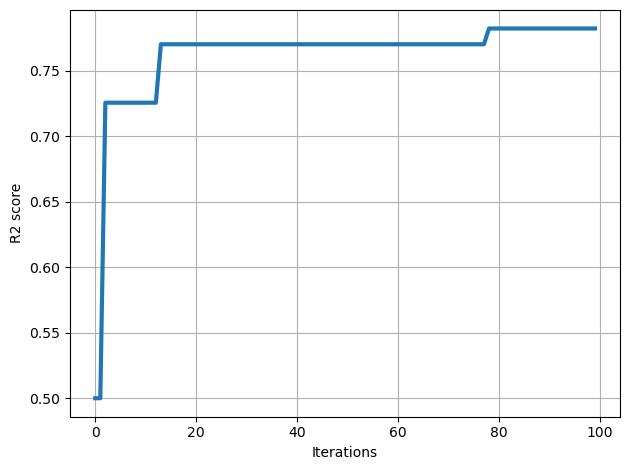

In [6]:
fig, ax = plt.subplots()

maxs = np.maximum.accumulate(-nn_opt.func_vals)
maxs = np.clip(maxs, 0.5, np.inf)
ax.plot(maxs, linewidth=3)

ax.set_xlabel("Iterations")
ax.set_ylabel("R2 score")
ax.grid()

fig.tight_layout()

In [7]:
best_x = nn_opt.x_iters[nn_opt.func_vals.argmin()]
print(f"Best params: {best_x}")

X_scaler = StandardScaler().fit(X_train)
X_train_t = X_scaler.transform(X_train)
X_train_v = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_t = y_scaler.transform(y_train)
y_train_v = y_scaler.transform(y_test)

model = build_model(*best_x[:-1])

n_epochs = 1000

model, train_losses, val_losses, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=best_x[-1], n_epochs=n_epochs, verbose=True)
print(f"Final test R2: {val_r2[-1]:.4f}")

Best params: [100, 0, 'sigmoid', 'no_final_relu', 0.01711126260505375]
[0] Train loss: 0.9101 (0.0899), Val loss: 0.6801 (0.2174)
[200] Train loss: 0.1804 (0.8196), Val loss: 0.1990 (0.7711)
[400] Train loss: 0.1640 (0.8360), Val loss: 0.1985 (0.7715)
[600] Train loss: 0.1605 (0.8395), Val loss: 0.1984 (0.7717)
[800] Train loss: 0.1596 (0.8404), Val loss: 0.1985 (0.7716)
[999] Train loss: 0.1594 (0.8406), Val loss: 0.1985 (0.7716)
Final test R2: 0.7716


In [36]:
class BestSVI(nn.Module):
    def __init__(self):
        super(BestSVI, self).__init__()
        self.fc1 = nn.Linear(59, 80)
        self.fc2 = nn.Linear(80, 1)
        self.lr = 0.012445653671345749

    def forward(self, x):
        x = F.tanh(self.fc1(x))
        x = self.fc2(x)
        return x

X_scaler = StandardScaler().fit(X_train)
X_train_t = X_scaler.transform(X_train)
X_train_v = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_t = y_scaler.transform(y_train)
y_train_v = y_scaler.transform(y_test)

model = BestSVI()

n_epochs = 200

model, train_losses, val_losses, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=model.lr, n_epochs=n_epochs, verbose=True)

[0] Train loss: 0.5858 (0.4142), Val loss: 0.4072 (0.5635)
[40] Train loss: 0.2209 (0.7791), Val loss: 0.2976 (0.6810)
[80] Train loss: 0.1934 (0.8066), Val loss: 0.2766 (0.7035)
[120] Train loss: 0.1785 (0.8215), Val loss: 0.2718 (0.7087)
[160] Train loss: 0.1685 (0.8315), Val loss: 0.2712 (0.7093)
[199] Train loss: 0.1628 (0.8372), Val loss: 0.2722 (0.7083)


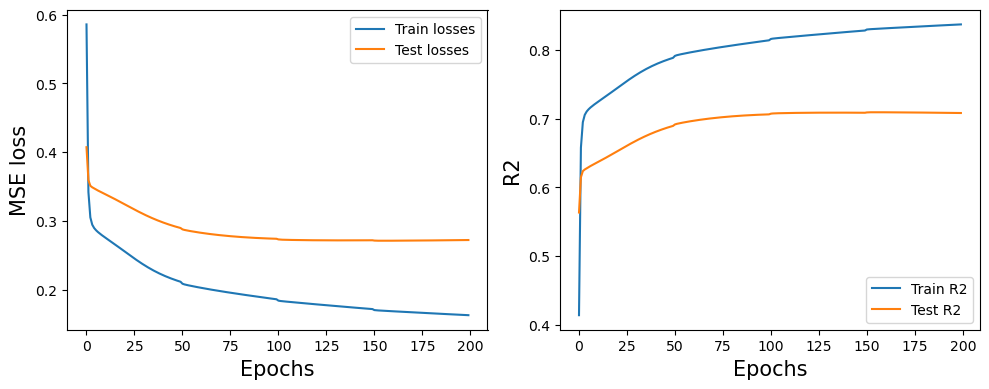

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(train_losses, label="Train losses")
ax[0].plot(val_losses, label="Test losses")

ax[0].set_xlabel('Epochs', fontsize=15)
ax[0].set_ylabel('MSE loss', fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].legend()

ax[1].plot(train_r2, label="Train R2")
ax[1].plot(val_r2, label="Test R2")

ax[1].set_xlabel('Epochs', fontsize=15)
ax[1].set_ylabel('R2', fontsize=15)
ax[1].tick_params(labelsize=10)
ax[1].legend()

fig.tight_layout()
# fig.savefig("nn_losses.png", dpi=150)

### Best NN different init same train/test

In [22]:
class BestS(nn.Module):
    def __init__(self):
        super(BestS, self).__init__()
        self.fc1 = nn.Linear(57, 100)
        self.fc2 = nn.Linear(100, 50)
        self.fc3 = nn.Linear(50, 1)
        self.lr = 0.011012775071632105

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    
class BestSV(nn.Module):
    def __init__(self):
        super(BestSV, self).__init__()
        self.fc1 = nn.Linear(58, 100)
        self.fc2 = nn.Linear(100, 1)
        self.lr = 0.01711126260505375

    def forward(self, x):
        x = F.sigmoid(self.fc1(x))
        x = self.fc2(x)
        return x

class BestSVI(nn.Module):
    def __init__(self):
        super(BestSVI, self).__init__()
        self.fc1 = nn.Linear(59, 80)
        self.fc2 = nn.Linear(80, 1)
        self.lr = 0.012445653671345749

    def forward(self, x):
        x = F.tanh(self.fc1(x))
        x = self.fc2(x)
        return x

In [29]:
X_scaler = StandardScaler().fit(X_train)
X_train_t = X_scaler.transform(X_train)
X_train_v = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_t = y_scaler.transform(y_train)
y_train_v = y_scaler.transform(y_test)

In [34]:
def one_train(i):
    model = BestSVI()
    
    _, train_loss, val_loss, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=model.lr, n_epochs=n_epochs, verbose=False)
    
    return train_loss, val_loss, train_r2, val_r2

n_epochs = 150
n = 8*2

res = Parallel(n_jobs=8)(delayed(one_train)(i) for i in range(n))

train_losses = np.array(res)[:,0]
val_losses = np.array(res)[:,1]
train_r2s = np.array(res)[:,2]
val_r2s = np.array(res)[:,3]

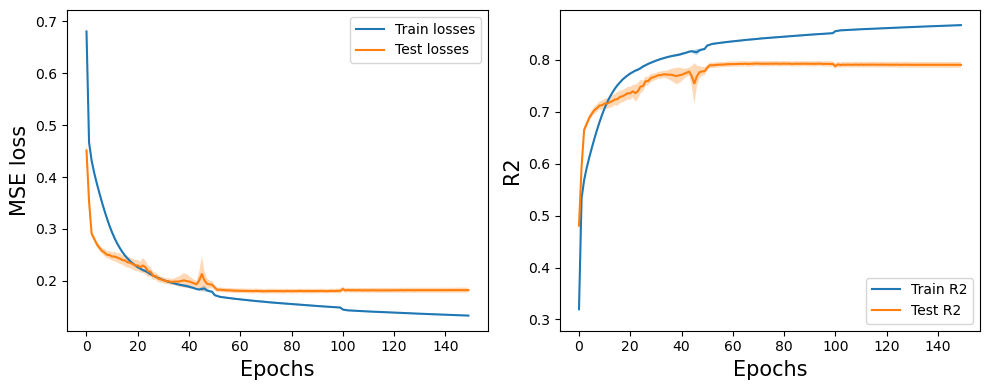

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

means = train_losses.mean(axis=0)
std_err = train_losses.std(axis=0)/np.sqrt(len(train_losses))
ax[0].plot(means, label="Train losses")
ax[0].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)

means = val_losses.mean(axis=0)
std_err = val_losses.std(axis=0)/np.sqrt(len(val_losses))
ax[0].plot(means, label="Test losses")
ax[0].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax[0].set_xlabel('Epochs', fontsize=15)
ax[0].set_ylabel('MSE loss', fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].legend()

means = train_r2s.mean(axis=0)
std_err = train_r2s.std(axis=0)/np.sqrt(len(train_r2s))
ax[1].plot(means, label="Train R2")
ax[1].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)

means = val_r2s.mean(axis=0)
std_err = val_r2s.std(axis=0)/np.sqrt(len(val_r2s))
ax[1].plot(means, label="Test R2")
ax[1].fill_between(range(len(means)), means-1.96*std_err, means+1.96*std_err, alpha=0.3)
# ax[1].plot(val_r2s.T, c='k', alpha=0.3, zorder=-1)

ax[1].set_xlabel('Epochs', fontsize=15)
ax[1].set_ylabel('R2', fontsize=15)
ax[1].tick_params(labelsize=10)
ax[1].legend()

fig.tight_layout()
# fig.savefig("nn_losses.png", dpi=150)

In [36]:
res_str(val_r2s[:,means.argmax()])

'0.7928 ± 0.0050'

With states: 0.7202 ± 0.0039

With states and votes: 0.7743 ± 0.0016

With states, votes, and incentives: 0.7878 ± 0.0028

### SHAP

In [86]:
import shap

features_simple = np.copy(features)
features_simple[:11] = ['avg GHI (W/m^2)',
            'number of households',
            'housing density (/mile^2)',
            'median income (inflation adjusted $)',
            '% housing occupied',
            '% housing occupied by renters',
            'avg years of education',
            'median age',
            'racial diversity (Gini Simpson index)',
            'fraction of dem votes',
            'level of incentives']

class BestSVI(nn.Module):
    def __init__(self):
        super(BestSVI, self).__init__()
        self.fc1 = nn.Linear(59, 80)
        self.fc2 = nn.Linear(80, 1)
        self.lr = 0.012445653671345749

    def forward(self, x):
        x = F.tanh(self.fc1(x))
        x = self.fc2(x)
        return x
    
model = BestSVI()
model.load_state_dict(torch.load("BestSVI_0.7889"))

def m_for_shap(X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X).float()).numpy()
    
X_scaler = StandardScaler().fit(X_train)
X_train_t = X_scaler.transform(X_train)
X_train_v = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_t = y_scaler.transform(y_train)
y_train_v = y_scaler.transform(y_test)

In [7]:
explainer = shap.Explainer(m_for_shap, X_train_v)
shap_values = explainer(X_train_v)

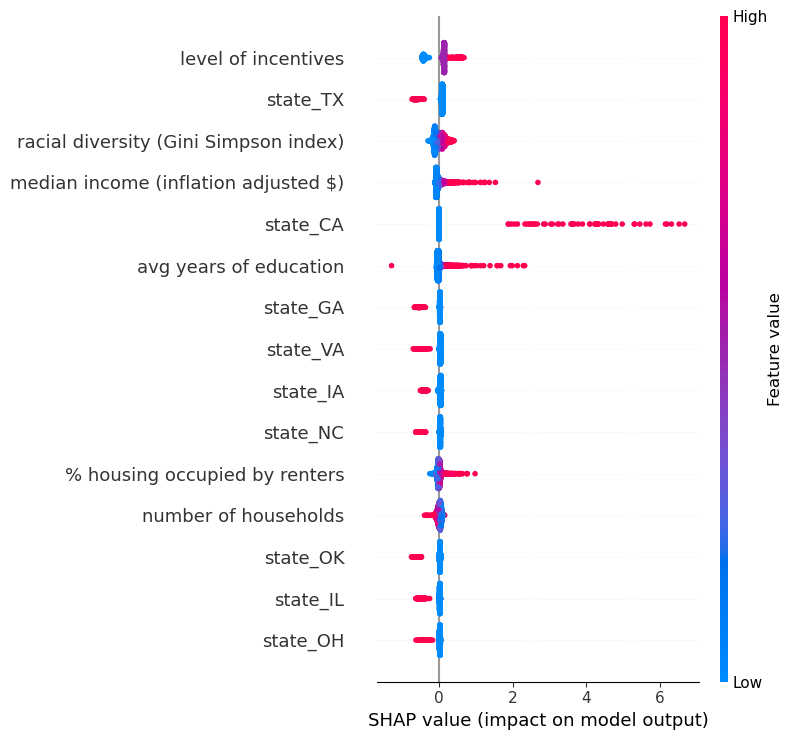

In [62]:
shap.summary_plot(shap_values, feature_names=features_simple, max_display=15, show=False)
# plt.savefig("../images/shap_values.png", dpi=150)

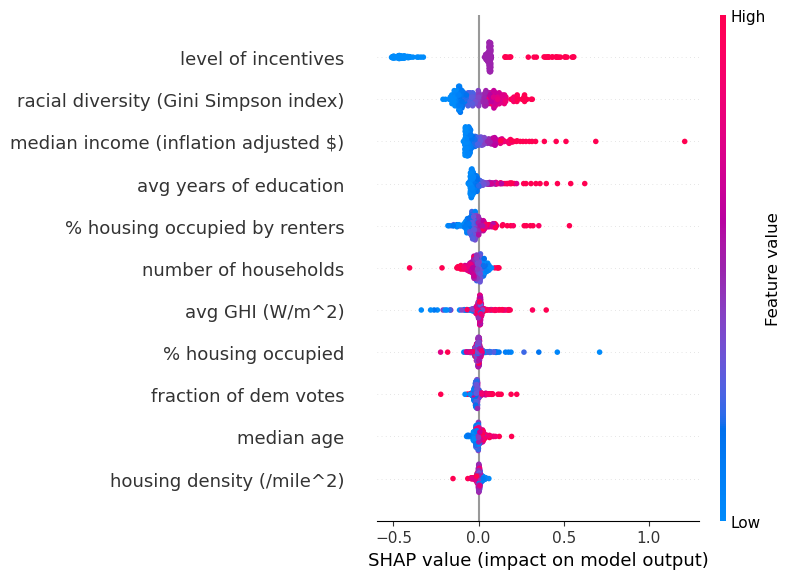

In [9]:
shap.summary_plot(shap_values[:,:11], feature_names=features_simple[:11], max_display=11, show=False)
# plt.savefig("../images/shap_values_focused.png", dpi=150)

In [99]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import ttest_ind
from sklearn.metrics import silhouette_score

In [100]:
explainer = shap.Explainer(m_for_shap, StandardScaler().fit_transform(X))
shap_values = explainer(StandardScaler().fit_transform(X))

Permutation explainer: 3105it [00:44, 56.14it/s]                                                                       


In [204]:
states = list(states_dict.values())
state_features = {}
state_features_non_scaled = {}

for s in states:
    mask = raw_data['state']==s
    
    if mask.sum()>10:
        state_x = StandardScaler().fit_transform(X)[mask].mean(axis=0)[:11]
        state_y = StandardScaler().fit_transform(y)[mask].mean()
        shaps = StandardScaler().fit_transform(np.abs(shap_values.values))[mask].mean(axis=0)[:11]
        state_features[s] = np.concatenate([state_x, [state_y], shaps])
        
        state_x = X[mask].mean(axis=0)[:11]
        state_y = y[mask].mean()
        shaps = np.abs(shap_values.values[mask]).mean(axis=0)[:11]
        state_features_non_scaled[s] = np.concatenate([state_x, [state_y], shaps])

shap_vals = np.array(list(state_features_non_scaled.values()))[:,-11:]
to_project = np.array(list(state_features_non_scaled.values()))[:,-11:]
to_project = np.array(list(state_features.values()))[:,-11:]

In [180]:
inertias = []
ks = np.arange(2, 8)

for k in ks:
    s = []
    i = []
    for _ in range(5):
        km = KMeans(n_clusters=k)
        clusters = km.fit_predict(to_project)
        i.append(km.inertia_)
        
    inertias.append(i)
    
inertias = np.array(inertias)

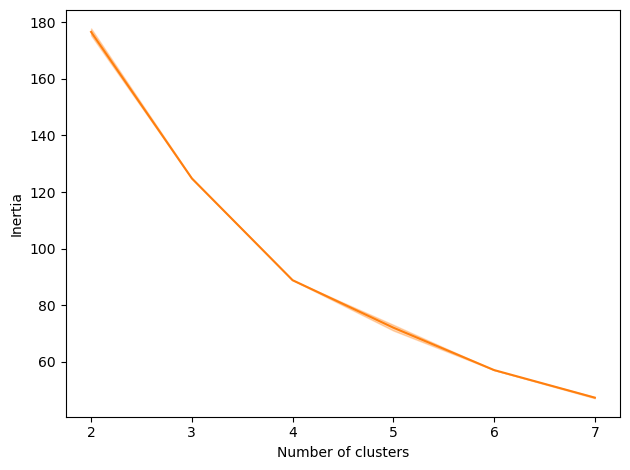

In [181]:
fig, ax = plt.subplots()

means = np.mean(inertias, axis=1)
std_err = np.std(inertias, axis=1)/np.sqrt(len(inertias[0]))
ax.plot(ks, means, color=plt_colours[1])
ax.fill_between(ks, means-1.96*std_err, means+1.96*std_err, alpha=0.3, color=plt_colours[1])

ax.set_xlabel("Number of clusters")
ax.set_ylabel("Inertia")

fig.tight_layout()

In [207]:
km = KMeans(n_clusters=5)
clusters = km.fit_predict(to_project)

pca_proj = False
if pca_proj:
    pca = PCA(n_components=2)
    proj = pca.fit_transform(to_project)
else:
    tsne = TSNE(n_components=2)
    proj = tsne.fit_transform(to_project)

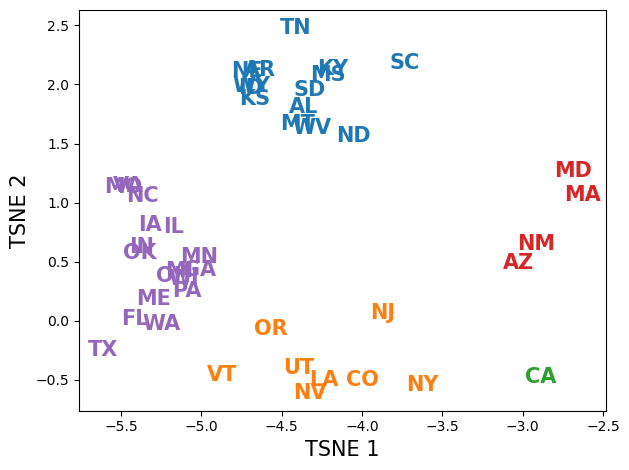

In [208]:
fig, ax = plt.subplots()

ax.scatter(proj[:,0], proj[:,1], alpha=0)

for c in range(km.n_clusters):
    for s, p in zip(np.array(list(state_features.keys()))[clusters==c], proj[clusters==c]):
        ax.text(p[0], p[1], s, fontsize=15, ha='center', va='center', c=plt_colours[c], fontweight='bold')

if pca_proj:
    ax.set_xlabel("PCA 1", fontsize=15)
    ax.set_ylabel("PCA 2", fontsize=15)
else:
    ax.set_xlabel("TSNE 1", fontsize=15)
    ax.set_ylabel("TSNE 2", fontsize=15)

fig.tight_layout()
# fig.savefig("../images/states_clustered_NN.png", dpi=150)

In [222]:
for c in range(km.n_clusters):
    mask = clusters==c
    states_in_cluster = np.array(list(state_features.keys()))[mask]
    mask = np.in1d(raw_data['state'].to_numpy(), states_in_cluster)
    
    print(", ".join(states_in_cluster))

AL, AR, ID, KS, KY, MS, MT, NE, ND, SC, SD, TN, WV, WY
CO, LA, NV, NJ, NY, OR, UT, VT
CA
AZ, MD, MA, NM
FL, GA, IL, IN, IA, ME, MI, MN, MO, NC, OH, OK, PA, TX, VA, WA, WI


In [209]:
p_val_thresh = 0.05

for c in range(km.n_clusters):
    mask = clusters==c
    states_in_cluster = np.array(list(state_features.keys()))[mask]
    mask = np.in1d(raw_data['state'].to_numpy(), states_in_cluster)
    
    print(f"Cluster {c} with {states_in_cluster}")
    
    for f in features[:11]:
        all_data = raw_data[f].to_numpy()
        in_cluster = raw_data[f][mask].to_numpy()
        
        p_val = ttest_ind(all_data, in_cluster)[1]
        if p_val<p_val_thresh:
            print(f"\t{f}: {all_data.mean():.4f} {in_cluster.mean():.4f} ({(in_cluster.mean() - all_data.mean())/in_cluster.mean()*100:.4f}%)")
            
    all_data = y.copy()
    in_cluster = y[mask]
    p_val = ttest_ind(all_data, in_cluster)[1]
    if p_val<=p_val_thresh:
        print(f"\tadoption: {all_data.mean():.4f} {in_cluster.mean():.4f} ({(in_cluster.mean() - all_data.mean())/in_cluster.mean()*100:.4f}%)")
    
    print("\n")

Cluster 0 with ['AL' 'AR' 'ID' 'KS' 'KY' 'MS' 'MT' 'NE' 'ND' 'SC' 'SD' 'TN' 'WV' 'WY']
	ACS: avg number of years of education (2016): 13.0463 12.9260 (-0.9312%)
	ACS: housing unit density (/mile^2, 2016): 533.5729 269.7675 (-97.7899%)
	ACS: median household income (inflation adjusted $ in 2016, 2016): 43565.8372 39991.1946 (-8.9386%)
	ACS: number of households (2016): 36936.2262 14718.1982 (-150.9562%)
	ACS: racial diversity (Gini Simpson index): 0.2455 0.2061 (-19.1267%)
	avg GHI (W/m^2): 186.4701 183.5229 (-1.6059%)
	frac_dem_votes: 0.3321 0.2776 (-19.6215%)
	incentive_level: 0.7648 0.0940 (-713.8678%)
	adoption: 0.0014 0.0001 (-1295.0191%)


Cluster 1 with ['CO' 'LA' 'NV' 'NJ' 'NY' 'OR' 'UT' 'VT']
	ACS: % housing units occupied (2016): 82.6144 81.1913 (-1.7527%)
	ACS: % housing units occupied by renters (2016): 28.3520 30.1255 (5.8870%)
	ACS: avg number of years of education (2016): 13.0463 13.3700 (2.4211%)
	ACS: housing unit density (/mile^2, 2016): 533.5729 1206.3044 (55.7680%)
	

In [210]:
p_val_thresh = 0.05

for c in range(km.n_clusters):
    mask = clusters==c
    states_in_cluster = np.array(list(state_features.keys()))[mask]
    
    print(f"Cluster {c} with {states_in_cluster}")
    
    for i, f in enumerate(features[:11]):
        all_data = shap_vals[:,i]
        in_cluster = shap_vals[:,i][mask]
        
        if mask.sum()>1:
            p_val = ttest_ind(all_data, in_cluster)[1]
            perc_diff = (in_cluster.mean() - all_data.mean())/in_cluster.mean()*100
            if p_val<=p_val_thresh and np.abs(perc_diff)>0:
                print(f"\t{f}: {all_data.mean():.4f} {in_cluster.mean():.4f} ({perc_diff:.4f}%)")
        else:
            perc_diff = (in_cluster[0] - all_data.mean())/in_cluster.mean()*100
            if p_val<=p_val_thresh and np.abs(perc_diff)>0:
                print(f"\t{f}: {all_data.mean():.4f} {in_cluster[0]:.4f} ({perc_diff:.4f}%)")
            
    print("\n")

Cluster 0 with ['AL' 'AR' 'ID' 'KS' 'KY' 'MS' 'MT' 'NE' 'ND' 'SC' 'SD' 'TN' 'WV' 'WY']
	avg GHI (W/m^2): 0.0999 0.0669 (-49.2999%)
	incentive_level: 0.2553 0.4296 (40.5767%)


Cluster 1 with ['CO' 'LA' 'NV' 'NJ' 'NY' 'OR' 'UT' 'VT']
	frac_dem_votes: 0.0183 0.0306 (40.2317%)
	incentive_level: 0.2553 0.1019 (-150.5151%)


Cluster 2 with ['CA']
	ACS: % housing units occupied (2016): 0.0331 0.2644 (87.4798%)
	ACS: % housing units occupied by renters (2016): 0.0391 0.0615 (36.3148%)
	ACS: avg number of years of education (2016): 0.0106 0.0156 (32.2669%)
	ACS: housing unit density (/mile^2, 2016): 0.0974 0.2986 (67.3749%)
	ACS: median age: 0.0283 0.2815 (89.9336%)
	ACS: median household income (inflation adjusted $ in 2016, 2016): 0.0512 0.2311 (77.8300%)
	ACS: number of households (2016): 0.0752 0.4605 (83.6718%)
	ACS: racial diversity (Gini Simpson index): 0.0164 0.0803 (79.5849%)
	avg GHI (W/m^2): 0.0999 0.0718 (-39.0186%)
	frac_dem_votes: 0.0183 0.0426 (57.0700%)
	incentive_level: 0.2553